# Stage 1 WP3 — Contract-driven Knowledge Graph

이 노트북은 Stage 1 WP2의 공식 산출물이 아직 확정되지 않은 상태에서 WP3 작업을 진행하기
위한 **계약 기반 분석 노트북**이다. 파일명과 열 이름을 분석 코드에 직접 고정하지 않고,
`config/wp3_open_models_contract.json`의 alias와 정책을 통해 WP2 결과를 canonical schema로
변환한다.

현재 실행 결과는 300문서 파일럿을 사용한 개발용 baseline이다. 공식 WP2 결과가 도착하면
입력 경로와 계약만 갱신한 뒤 동일한 셀을 다시 실행해야 한다.

## 1. 실행 경로와 교체 지점

공식 WP2 결과가 도착했을 때 우선 변경할 부분은 아래 셀의 `WP2_INPUT_DIR`이다. 파일명이나
열 이름이 달라졌다면 원본 파일을 수동으로 바꾸지 말고 `CONTRACT_PATH`의 JSON에 후보 파일명과
alias를 추가한다.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "config").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

WP2_INPUT_DIR = ROOT / "outputs" / "stage1_wp2_open_models_pilot"
WP3_OUTPUT_DIR = ROOT / "outputs" / "stage1_wp3_open_models_pilot"
CONTRACT_PATH = ROOT / "config" / "wp3_open_models_contract.json"

# 공식 WP2 입력으로 graph artifacts를 다시 만들 때만 True로 변경한다.
RUN_PIPELINE = False

ROOT, WP2_INPUT_DIR, WP3_OUTPUT_DIR, CONTRACT_PATH

(WindowsPath('C:/Users/wldhg/Documents/code/computational_language'),
 WindowsPath('C:/Users/wldhg/Documents/code/computational_language/outputs/stage1_wp2_open_models_pilot'),
 WindowsPath('C:/Users/wldhg/Documents/code/computational_language/outputs/stage1_wp3_open_models_pilot'),
 WindowsPath('C:/Users/wldhg/Documents/code/computational_language/config/wp3_open_models_contract.json'))

## 2. WP2→WP3 입력 계약 확인

In [2]:
contract = json.loads(CONTRACT_PATH.read_text(encoding="utf-8"))

contract_overview = []
for table_name, spec in contract["tables"].items():
    contract_overview.append({
        "table": table_name,
        "required": spec.get("required", False),
        "candidate_files": ", ".join(spec.get("files", [])),
        "required_fields": ", ".join(spec.get("required_fields", [])),
    })

print("contract_version:", contract["contract_version"])
pd.DataFrame(contract_overview)

contract_version: wp2-to-wp3-draft-v1


,table,required,candidate_files,required_fields
0,entities,True,"entities.parquet, entities.csv, nodes.parquet,...","entity_id, canonical_name, entity_type"
1,relations,True,"relations.parquet, relations.csv, edges.parque...","subject_id, predicate, object_id"
2,cooccurrence,False,"cooccurrence_edges.parquet, cooccurrence_edges...","source_id, target_id"
3,documents,False,"documents.parquet, documents.csv",document_id
4,text_units,False,"text_units.parquet, text_units.csv, sentences....","text_unit_id, document_id"
5,reviews,False,"relation_review_sample.csv, relation_reviews.csv",relation_id


In [3]:
pd.DataFrame([
    {"policy": key, "value": json.dumps(value, ensure_ascii=False)}
    for key, value in contract["policies"].items()
])

,policy,value
0,allowed_assertion_statuses,"[""asserted""]"
1,exclude_reviewed_false,true
2,require_reviewed_true,false
3,drop_self_relations,true
4,strict_schema,true
5,include_isolated_nodes,false
6,minimum_rule_score,null
7,minimum_cooccurrence_documents,1
8,required_relation_provenance,"[""document_id"", ""text_unit_id"", ""evidence_text""]"
9,strict_provenance,false


계약은 다음 변경을 흡수한다.

- Parquet과 CSV 파일명 변경
- `entity_id` 대신 `id`/`node_id` 사용
- `subject_id/predicate/object_id` 대신 `source/relation/target` 사용
- review, documents, text units, co-occurrence 같은 선택 입력의 추가·누락
- assertion status, confidence threshold, provenance 엄격성 변경

공식 계약이 확정되면 `strict_provenance`를 `true`로 바꾸어 evidence 연결이 없는 관계를
graph 생성 전에 차단하는 것이 권장된다.

## 3. 필요할 때 파이프라인 재실행

In [4]:
if RUN_PIPELINE:
    from wp3_knowledge_graph import WP3PipelineConfig, run_pipeline

    pipeline_summary = run_pipeline(
        WP3PipelineConfig(
            input_dir=WP2_INPUT_DIR,
            output_dir=WP3_OUTPUT_DIR,
            contract_path=CONTRACT_PATH,
        )
    )
    display(pd.json_normalize(pipeline_summary))
else:
    print("기존 WP3 산출물을 사용합니다. 공식 WP2 입력으로 교체할 때 RUN_PIPELINE=True로 설정하세요.")

기존 WP3 산출물을 사용합니다. 공식 WP2 입력으로 교체할 때 RUN_PIPELINE=True로 설정하세요.


## 4. 실제로 해석된 계약과 validation 결과

In [5]:
contract_report = json.loads(
    (WP3_OUTPUT_DIR / "contract_report.json").read_text(encoding="utf-8")
)
validation = json.loads(
    (WP3_OUTPUT_DIR / "validation_report.json").read_text(encoding="utf-8")
)

resolved_tables = pd.DataFrame([
    {
        "table": name,
        "rows": details["rows"],
        "resolved_file": Path(details["path"]).name,
        "resolved_columns": json.dumps(details["resolved_columns"], ensure_ascii=False),
    }
    for name, details in contract_report["tables"].items()
])

display(resolved_tables)
display(pd.DataFrame({
    "check": [key for key in validation if key not in {"errors", "warnings"}],
    "result": [validation[key] for key in validation if key not in {"errors", "warnings"}],
}))
print("warnings:", validation["warnings"])
print("errors:", validation["errors"])
assert validation["passed"], '입력 계약 또는 graph integrity validation이 실패했습니다.'

,table,rows,resolved_file,resolved_columns
0,entities,1288,entities.parquet,"{""entity_id"": ""entity_id"", ""canonical_name"": ""..."
1,relations,1647,relations.parquet,"{""relation_id"": ""relation_id"", ""subject_id"": ""..."
2,cooccurrence,4230,cooccurrence_edges.parquet,"{""source_id"": ""source_id"", ""target_id"": ""targe..."
3,documents,300,documents.parquet,"{""document_id"": ""document_id"", ""title"": ""title..."
4,text_units,26579,text_units.parquet,"{""text_unit_id"": ""text_unit_id"", ""document_id""..."
5,reviews,87,relation_review_sample.csv,"{""relation_id"": ""relation_id"", ""review_correct..."


,check,result
0,duplicate_entity_ids,0
1,duplicate_relation_ids,0
2,null_entity_keys,0
3,null_relation_keys,0
4,dangling_relation_subjects,0
5,dangling_relation_objects,0
6,self_relations,0
7,invalid_relation_signatures,0
8,dangling_cooccurrence_endpoints,0
9,missing_relation_provenance,"{'document_id': 0, 'text_unit_id': 0, 'evidenc..."


warnings: []
errors: []


Validation 통과는 ID, endpoint, schema signature, provenance 같은 구조적 조건이
충족됐다는 뜻이다. 자동으로 추출된 relation의 의미가 모두 정확하다는 뜻은 아니며, 이는
`relation_review_sample.csv`의 수동 검수로 별도 평가해야 한다.

## 5. Graph view와 policy 적용 결과

In [6]:
summary = json.loads(
    (WP3_OUTPUT_DIR / "graph_summary.json").read_text(encoding="utf-8")
)

display(pd.DataFrame([
    {"graph_view": name, **statistics}
    for name, statistics in summary["graphs"].items()
]))
display(pd.DataFrame([
    {"policy_step": key, "relation_count": value}
    for key, value in summary["policy_audit"].items()
]))

,graph_view,nodes,edges,unique_node_pairs,simple_density,weakly_connected_components,isolated_nodes,connected_components
0,assertion,43,1644,63,0.034884,1.0,0,NaN
1,typed,43,66,63,0.034884,1.0,0,NaN
2,cooccurrence,1288,4230,4230,0.005104,NaN,0,1.0


,policy_step,relation_count
0,input_relations,1647
1,excluded_by_assertion_status,3
2,excluded_by_negative_review,0
3,excluded_self_relations,0
4,included_relations,1644


세 graph view의 목적은 다르다.

- **Assertion graph**: evidence별 edge를 유지하여 provenance와 Stage 3 retrieval에 사용한다.
- **Collapsed typed graph**: 같은 `(subject, predicate, object)`를 합쳐 metric과 발표용 분석에 사용한다.
- **Co-occurrence graph**: 같은 문장에 나타난 엔티티를 연결하며 community와 담론 구조 분석에 사용한다.

Assertion 수를 unique fact 수로 해석하거나, 공동출현을 의미 관계로 해석하면 안 된다.

## 6. Collapsed typed relations

In [7]:
nodes = pd.read_parquet(WP3_OUTPUT_DIR / "nodes.parquet")
assertions = pd.read_parquet(WP3_OUTPUT_DIR / "typed_edges_assertions.parquet")
typed_edges = pd.read_parquet(WP3_OUTPUT_DIR / "typed_edges_collapsed.parquet")
cooccurrence = pd.read_parquet(WP3_OUTPUT_DIR / "cooccurrence_edges.parquet")
metrics = pd.read_parquet(WP3_OUTPUT_DIR / "node_metrics.parquet")

labels = nodes.set_index("entity_id")["canonical_name"]
typed_view = typed_edges.assign(
    subject_label=typed_edges["subject_id"].map(labels),
    object_label=typed_edges["object_id"].map(labels),
)

display(typed_view["predicate"].value_counts().rename_axis("predicate").reset_index(name="unique_edges"))
typed_view.sort_values(
    ["document_count", "evidence_count"], ascending=False
)[[
    "subject_label", "predicate", "object_label", "evidence_count",
    "document_count", "domain_count", "first_seen", "last_seen",
]].head(25)

,predicate,unique_edges
0,BELONGS_TO_FAMILY,19
1,USES_ARCHITECTURE,15
2,HAS_CAPABILITY,11
3,LICENSED_UNDER,9
4,RELEASED_BY,7
5,DEVELOPED_BY,4
6,DERIVED_FROM,1


,subject_label,predicate,object_label,evidence_count,document_count,domain_count,first_seen,last_seen
0,DeepSeek-R1,BELONGS_TO_FAMILY,DeepSeek,198,38,19,2024-11-27,2026-08-11
18,Qwen3,BELONGS_TO_FAMILY,Qwen,151,36,13,2025-05-01,2026-08-07
4,Gemma 3,BELONGS_TO_FAMILY,Gemma,98,27,11,2025-03-01,2026-08-11
7,Llama 3,BELONGS_TO_FAMILY,Llama,64,26,11,2024-09-18,2026-08-11
5,Gemma 4,BELONGS_TO_FAMILY,Gemma,352,25,6,2026-03-11,2026-08-24
8,Llama 3.1,BELONGS_TO_FAMILY,Llama,112,23,12,2024-09-18,2026-08-11
2,DeepSeek-V3,BELONGS_TO_FAMILY,DeepSeek,92,21,13,2024-12-25,2026-08-11
9,Llama 3.2,BELONGS_TO_FAMILY,Llama,237,18,11,2024-09-18,2026-08-11
17,Qwen2.5,BELONGS_TO_FAMILY,Qwen,52,17,7,2024-11-13,2026-08-11
6,Llama 2,BELONGS_TO_FAMILY,Llama,32,11,11,2024-09-25,2026-08-11


`document_count`는 서로 다른 source document 수이고 `evidence_count`는 문장별
assertion 수다. 반복 모델 카드나 유사 기사에 덜 민감하도록 기본 시각화와 weighted metric에는
`document_count`를 사용한다.

## 7. Network metrics

In [8]:
metric_columns = [
    "canonical_name", "entity_type", "degree", "weighted_degree",
    "pagerank", "betweenness", "clustering",
]

print("Collapsed typed graph")
display(
    metrics[metrics["graph_view"] == "typed"]
    .sort_values("pagerank", ascending=False)
    .head(15)[metric_columns]
)

print("Co-occurrence graph")
display(
    metrics[metrics["graph_view"] == "cooccurrence"]
    .sort_values("pagerank", ascending=False)
    .head(15)[metric_columns]
)

Collapsed typed graph


,canonical_name,entity_type,degree,weighted_degree,pagerank,betweenness,clustering
0,Llama,MODEL_FAMILY,11,104.0,0.102891,0.401858,0.008773
1,Gemma,MODEL_FAMILY,6,68.0,0.074449,0.160279,0.027926
2,Qwen,MODEL_FAMILY,5,64.0,0.068769,0.144019,0.000000
3,DeepSeek,MODEL_FAMILY,4,64.0,0.064820,0.191638,0.051256
4,Qwen3,MODEL,6,44.0,0.047694,0.254355,0.000000
5,DeepSeek-R1,MODEL,6,45.0,0.047517,0.126597,0.024923
6,Phi-4,MODEL,5,13.0,0.040196,0.139373,0.000000
7,Gemma 4,MODEL,5,35.0,0.039786,0.030197,0.069816
8,Mistral,MODEL_FAMILY,6,18.0,0.038671,0.211382,0.006039
9,Phi,MODEL_FAMILY,2,10.0,0.032119,0.047619,0.000000


Co-occurrence graph


,canonical_name,entity_type,degree,weighted_degree,pagerank,betweenness,clustering
43,Google,ORGANIZATION,304,606.0,0.045904,0.526580,0.001122
44,Meta,ORGANIZATION,251,593.0,0.039130,0.437230,0.001759
45,Llama,MODEL_FAMILY,235,476.0,0.033424,0.252395,0.001571
46,Microsoft,ORGANIZATION,209,365.0,0.026780,0.187906,0.001440
47,Mistral,MODEL_FAMILY,137,207.0,0.016419,0.075783,0.002131
48,Gemma 4,MODEL,110,186.0,0.016282,0.089488,0.001883
49,Hugging Face,ORGANIZATION,117,219.0,0.016143,0.062693,0.002588
50,Gemma,MODEL_FAMILY,107,205.0,0.015311,0.097606,0.002372
51,AI,ORGANIZATION,109,220.0,0.014745,0.112032,0.004579
52,DeepSeek-R1,MODEL,95,166.0,0.012332,0.053723,0.004045


현재 metric은 300문서 파일럿과 현재 graph policy 안에서의 연결성을 나타낸다.
실제 산업 영향력이나 모델 성능 순위로 해석할 수 없다. 또한 typed graph의 방향은 relation에
따라 의미가 다르므로, 최종 분석에서는 predicate별 subgraph를 함께 제시해야 한다.

## 8. 관계 유형별 지표와 시간 변화

In [9]:
relation_summary = pd.read_parquet(WP3_OUTPUT_DIR / "relation_type_summary.parquet")
monthly_assertions = pd.read_parquet(WP3_OUTPUT_DIR / "monthly_relation_assertions.parquet")
monthly_entities = pd.read_parquet(WP3_OUTPUT_DIR / "monthly_new_entities.parquet")
monthly_edges = pd.read_parquet(WP3_OUTPUT_DIR / "monthly_new_typed_edges.parquet")

display(relation_summary)
display(monthly_assertions.tail(20))

predicate_metrics = metrics[metrics["graph_view"].str.startswith("predicate:", na=False)]
display(
    predicate_metrics.sort_values(["graph_view", "pagerank"], ascending=[True, False])
    .groupby("graph_view", as_index=False)
    .head(5)[["graph_view", *metric_columns]]
)

,predicate,unique_edges,subject_nodes,object_nodes,total_evidence,total_documents,first_seen,last_seen
0,BELONGS_TO_FAMILY,19,19,6,1550,292,2024-09-18,2026-08-24
1,USES_ARCHITECTURE,15,12,3,35,32,2024-09-18,2026-08-11
2,HAS_CAPABILITY,11,8,5,11,11,2024-11-26,2026-07-16
3,LICENSED_UNDER,9,8,3,17,17,2025-06-04,2026-07-14
4,RELEASED_BY,7,7,6,15,14,2024-09-26,2026-08-11
5,DEVELOPED_BY,4,4,3,14,14,2024-10-04,2026-08-11
6,DERIVED_FROM,1,1,1,2,2,2025-01-20,2025-12-03


,month,predicate,assertion_count,document_count
52,2026-03,LICENSED_UNDER,2,2
53,2026-04,BELONGS_TO_FAMILY,62,8
54,2026-04,DEVELOPED_BY,2,2
55,2026-04,LICENSED_UNDER,3,3
56,2026-04,RELEASED_BY,3,3
57,2026-05,BELONGS_TO_FAMILY,165,13
58,2026-05,DEVELOPED_BY,3,3
59,2026-05,HAS_CAPABILITY,1,1
60,2026-05,LICENSED_UNDER,1,1
61,2026-05,RELEASED_BY,2,2


,graph_view,canonical_name,entity_type,degree,weighted_degree,pagerank,betweenness,clustering
1331,predicate:BELONGS_TO_FAMILY,Llama,MODEL_FAMILY,5,88.0,0.113512,0.036232,0.0
1332,predicate:BELONGS_TO_FAMILY,DeepSeek,MODEL_FAMILY,3,63.0,0.076756,0.010870,0.0
1333,predicate:BELONGS_TO_FAMILY,Mistral,MODEL_FAMILY,3,13.0,0.076756,0.010870,0.0
1334,predicate:BELONGS_TO_FAMILY,Qwen,MODEL_FAMILY,3,60.0,0.076756,0.010870,0.0
1335,predicate:BELONGS_TO_FAMILY,Gemma,MODEL_FAMILY,3,58.0,0.076756,0.010870,0.0
1356,predicate:DERIVED_FROM,DeepSeek-R1,MODEL,1,2.0,0.500000,0.000000,0.0
1357,predicate:DERIVED_FROM,DeepSeek-V3,MODEL,1,2.0,0.500000,0.000000,0.0
1358,predicate:DEVELOPED_BY,Google,ORGANIZATION,2,8.0,0.208493,0.066667,0.0
1359,predicate:DEVELOPED_BY,Llama,MODEL_FAMILY,1,5.0,0.142857,0.000000,0.0
1360,predicate:DEVELOPED_BY,Meta,ORGANIZATION,1,5.0,0.142857,0.000000,0.0


관계 유형별 graph를 분리하면 방향과 의미가 다른 edge를 한꺼번에 합산하는 오류를
줄일 수 있다. 월별 표는 데이터 수집량 변화에도 영향을 받으므로, 상승·하락을 실제 시장 변화로
확정하기 전에 월별 document 수와 원문 evidence를 함께 확인해야 한다.

## 9. Co-occurrence community와 검토 후보

In [10]:
communities = pd.read_parquet(WP3_OUTPUT_DIR / "node_communities.parquet")
community_summary = pd.read_parquet(WP3_OUTPUT_DIR / "community_summary.parquet")
finding_candidates = pd.read_parquet(WP3_OUTPUT_DIR / "graph_finding_candidates.parquet")

display(community_summary.head(15))
display(
    communities.sort_values(["community_id", "rank_in_community"])
    .groupby("community_id", as_index=False)
    .head(5)
    .head(50)
)
display(finding_candidates.head(30))
assert set(finding_candidates["review_status"]) <= {"unreviewed", "accepted", "rejected"}

,community_id,node_count,edge_count,top_entities
0,1,279,605,"[""Google"", ""Microsoft"", ""Gemma"", ""AI"", ""OpenAI..."
1,2,245,595,"[""Qwen"", ""DeepSeek-R1"", ""Alibaba"", ""DeepSeek"",..."
2,3,222,530,"[""Meta"", ""Llama"", ""Llama 3.2"", ""Llama 3.1"", ""B..."
3,4,133,281,"[""Mistral"", ""Mistral AI"", ""Arthur Mensch"", ""Am..."
4,5,120,231,"[""Hugging Face"", ""SGLang"", ""Apache License 2.0..."
5,6,118,160,"[""Gemma 4"", ""Long Context"", ""Gemma 3"", ""Multil..."
6,7,25,56,"[""Allen Institute for AI"", ""University of Wash..."
7,8,22,35,"[""BLOOM"", ""Cine-Forest: Awakening"", ""KAIST Art..."
8,9,20,142,"[""the European Commission"", ""Agoro Carbon"", ""A..."
9,10,16,44,"[""HTML"", ""Amazon CodeWhisperer"", ""Express"", ""G..."


,community_id,community_size,rank_in_community,entity_id,canonical_name,entity_type,weighted_degree_in_community
0,1,279,1,org:google,Google,ORGANIZATION,349.0
1,1,279,2,org:microsoft,Microsoft,ORGANIZATION,223.0
2,1,279,3,family:gemma,Gemma,MODEL_FAMILY,112.0
3,1,279,4,org:ai,AI,ORGANIZATION,73.0
4,1,279,5,org:openai,OpenAI,ORGANIZATION,63.0
279,2,245,1,family:qwen,Qwen,MODEL_FAMILY,114.0
280,2,245,2,model:deepseek_r1,DeepSeek-R1,MODEL,112.0
281,2,245,3,org:alibaba,Alibaba,ORGANIZATION,112.0
282,2,245,4,product:deepseek,DeepSeek,PRODUCT_OTHER,90.0
283,2,245,5,model:qwen_3,Qwen3,MODEL,76.0


,candidate_type,rank,entity_or_pair,predicate,metric_name,metric_value,document_count,evidence_count,first_seen,last_seen,supporting_ids,review_status
0,top_pagerank_typed,1,Llama,NaN,pagerank,0.102891,NaN,NaN,NaN,NaN,"[""family:llama""]",unreviewed
1,top_pagerank_typed,2,Gemma,NaN,pagerank,0.074449,NaN,NaN,NaN,NaN,"[""family:gemma""]",unreviewed
2,top_pagerank_typed,3,Qwen,NaN,pagerank,0.068769,NaN,NaN,NaN,NaN,"[""family:qwen""]",unreviewed
3,top_pagerank_typed,4,DeepSeek,NaN,pagerank,0.064820,NaN,NaN,NaN,NaN,"[""family:deepseek""]",unreviewed
4,top_pagerank_typed,5,Qwen3,NaN,pagerank,0.047694,NaN,NaN,NaN,NaN,"[""model:qwen_3""]",unreviewed
5,top_pagerank_typed,6,DeepSeek-R1,NaN,pagerank,0.047517,NaN,NaN,NaN,NaN,"[""model:deepseek_r1""]",unreviewed
6,top_pagerank_typed,7,Phi-4,NaN,pagerank,0.040196,NaN,NaN,NaN,NaN,"[""model:phi_4""]",unreviewed
7,top_pagerank_typed,8,Gemma 4,NaN,pagerank,0.039786,NaN,NaN,NaN,NaN,"[""model:gemma_4""]",unreviewed
8,top_pagerank_typed,9,Mistral,NaN,pagerank,0.038671,NaN,NaN,NaN,NaN,"[""family:mistral""]",unreviewed
9,top_pagerank_typed,10,Phi,NaN,pagerank,0.032119,NaN,NaN,NaN,NaN,"[""family:phi""]",unreviewed


`graph_finding_candidates`는 결론이 아니라 사람의 검토 대기열이다. 최종 보고서에
사용할 항목은 연결된 entity/relation/text unit을 원문과 대조한 뒤 `accepted` 또는 `rejected`로
표시해야 한다. 공동출현 community도 의미 관계나 인과관계를 직접 뜻하지 않는다.

## 10. 자동 생성된 시각화 점검

typed_graph_top.png


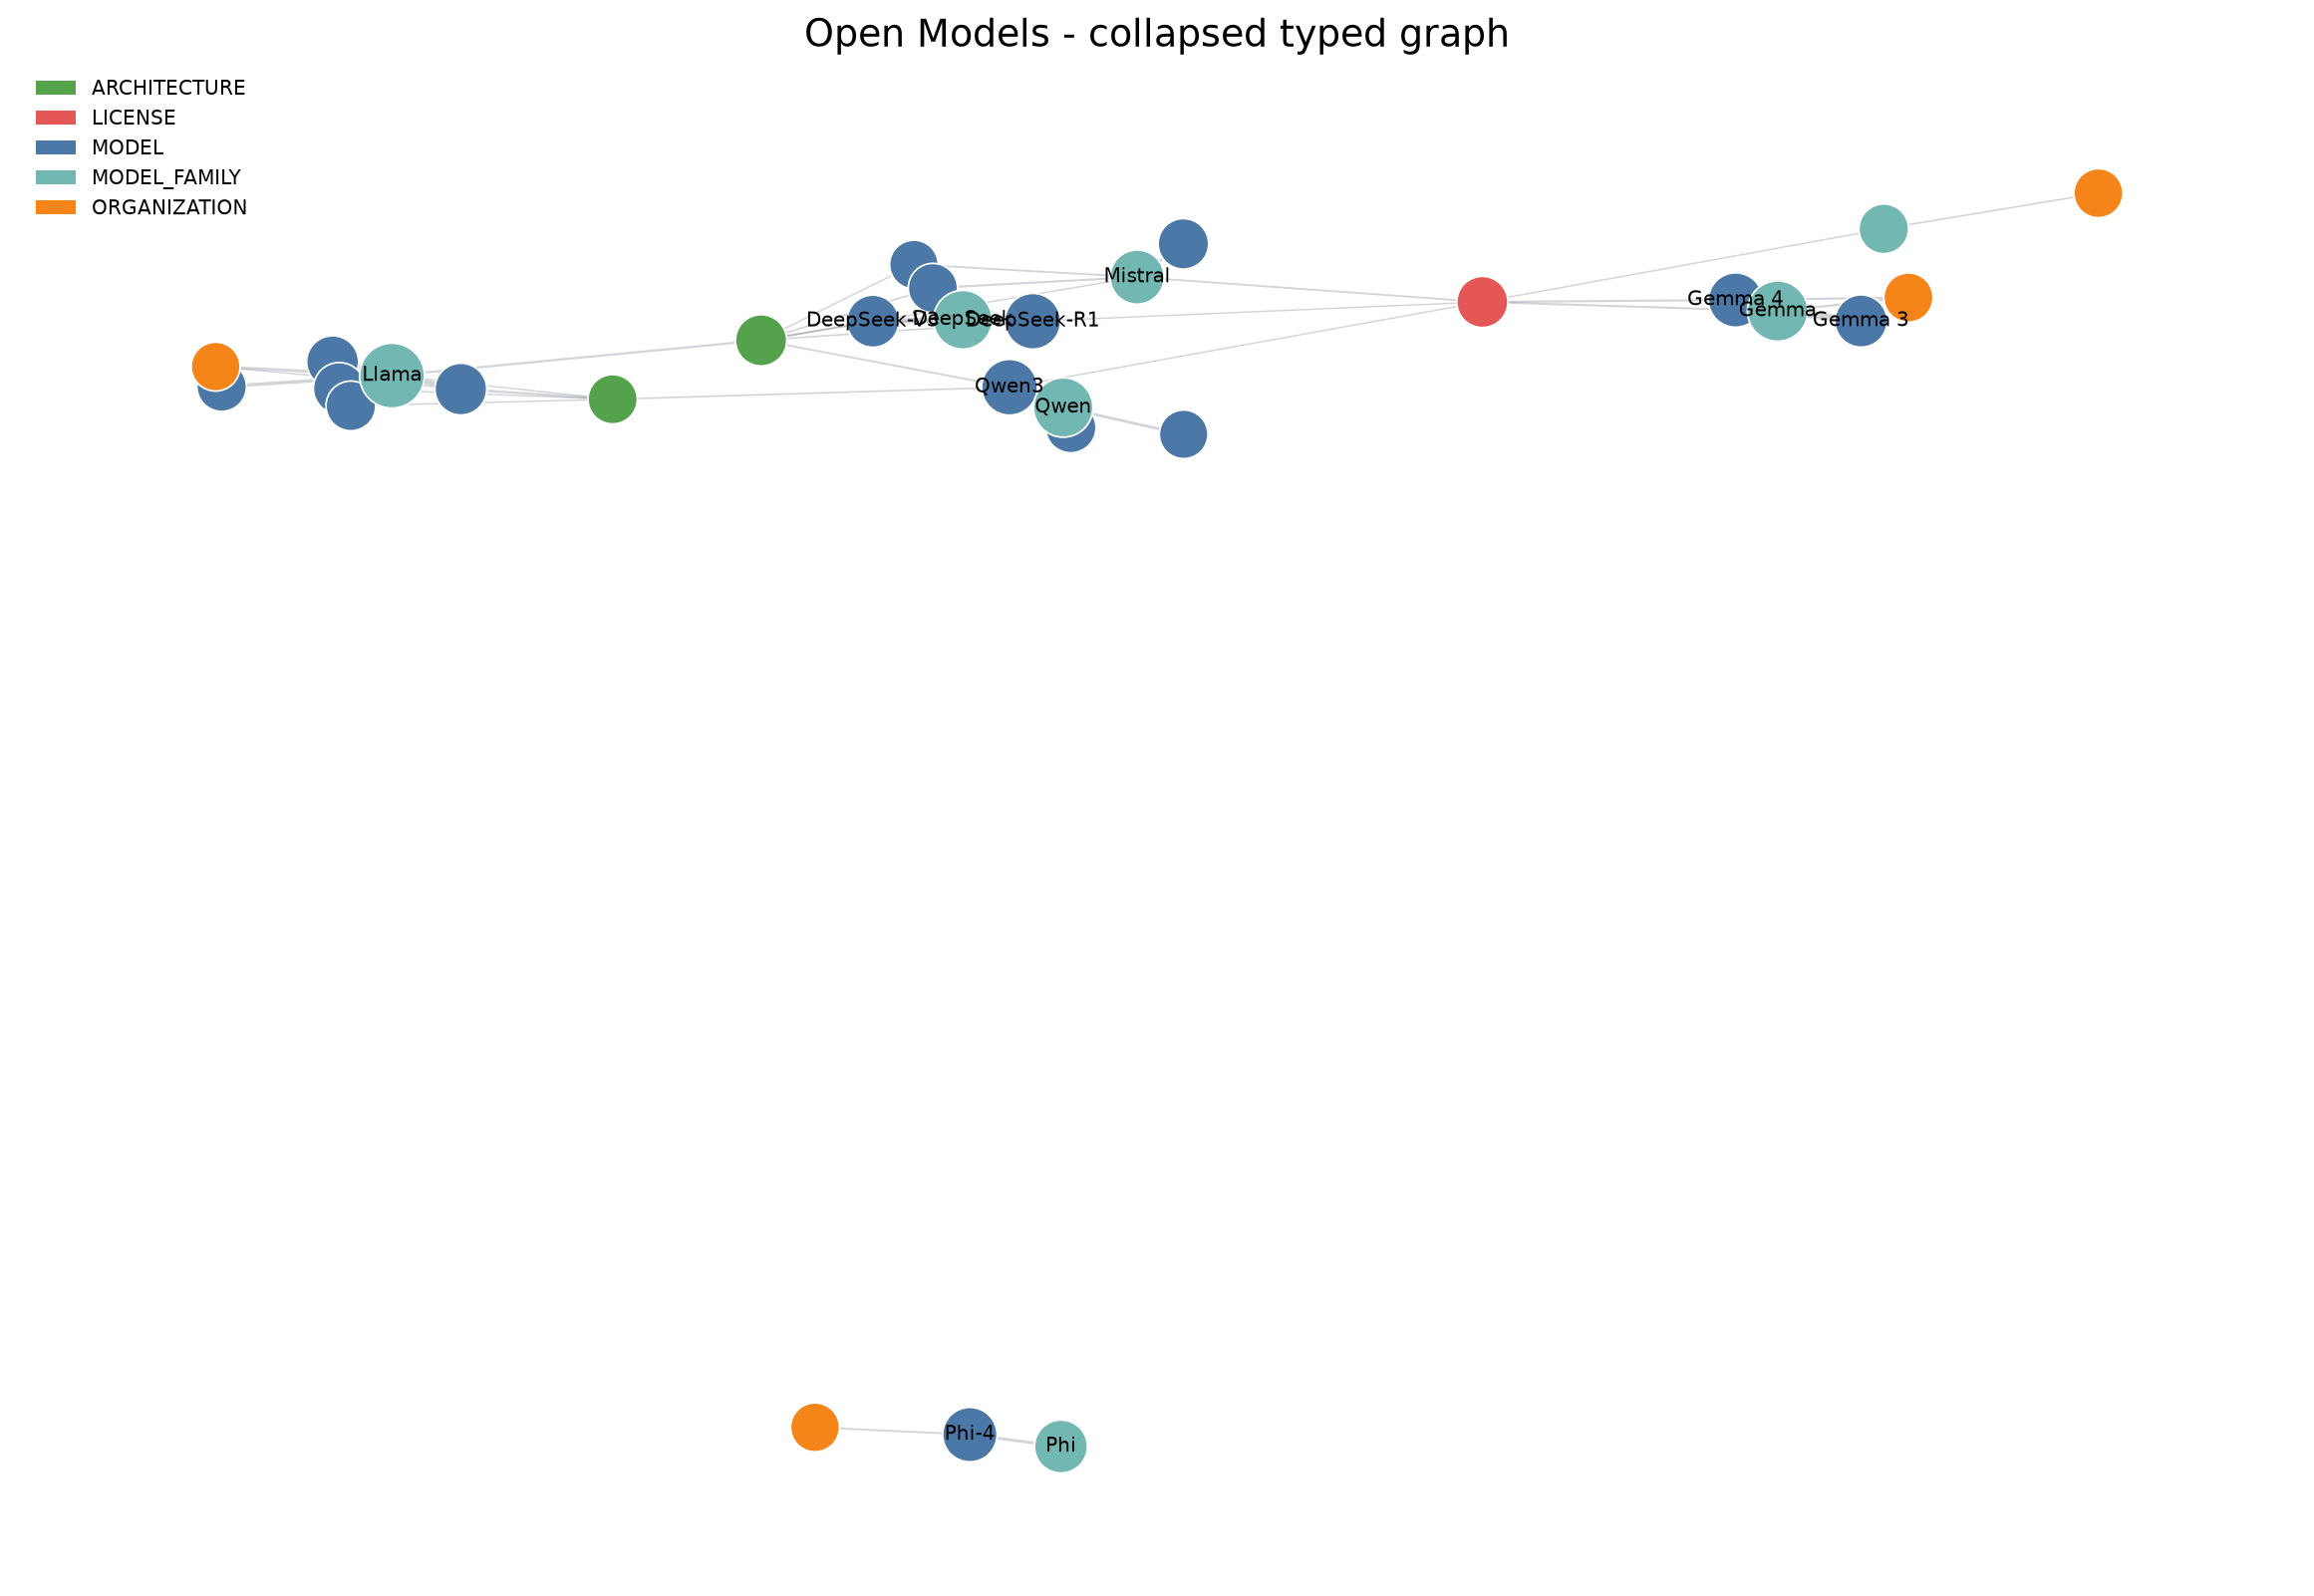

cooccurrence_graph_top.png


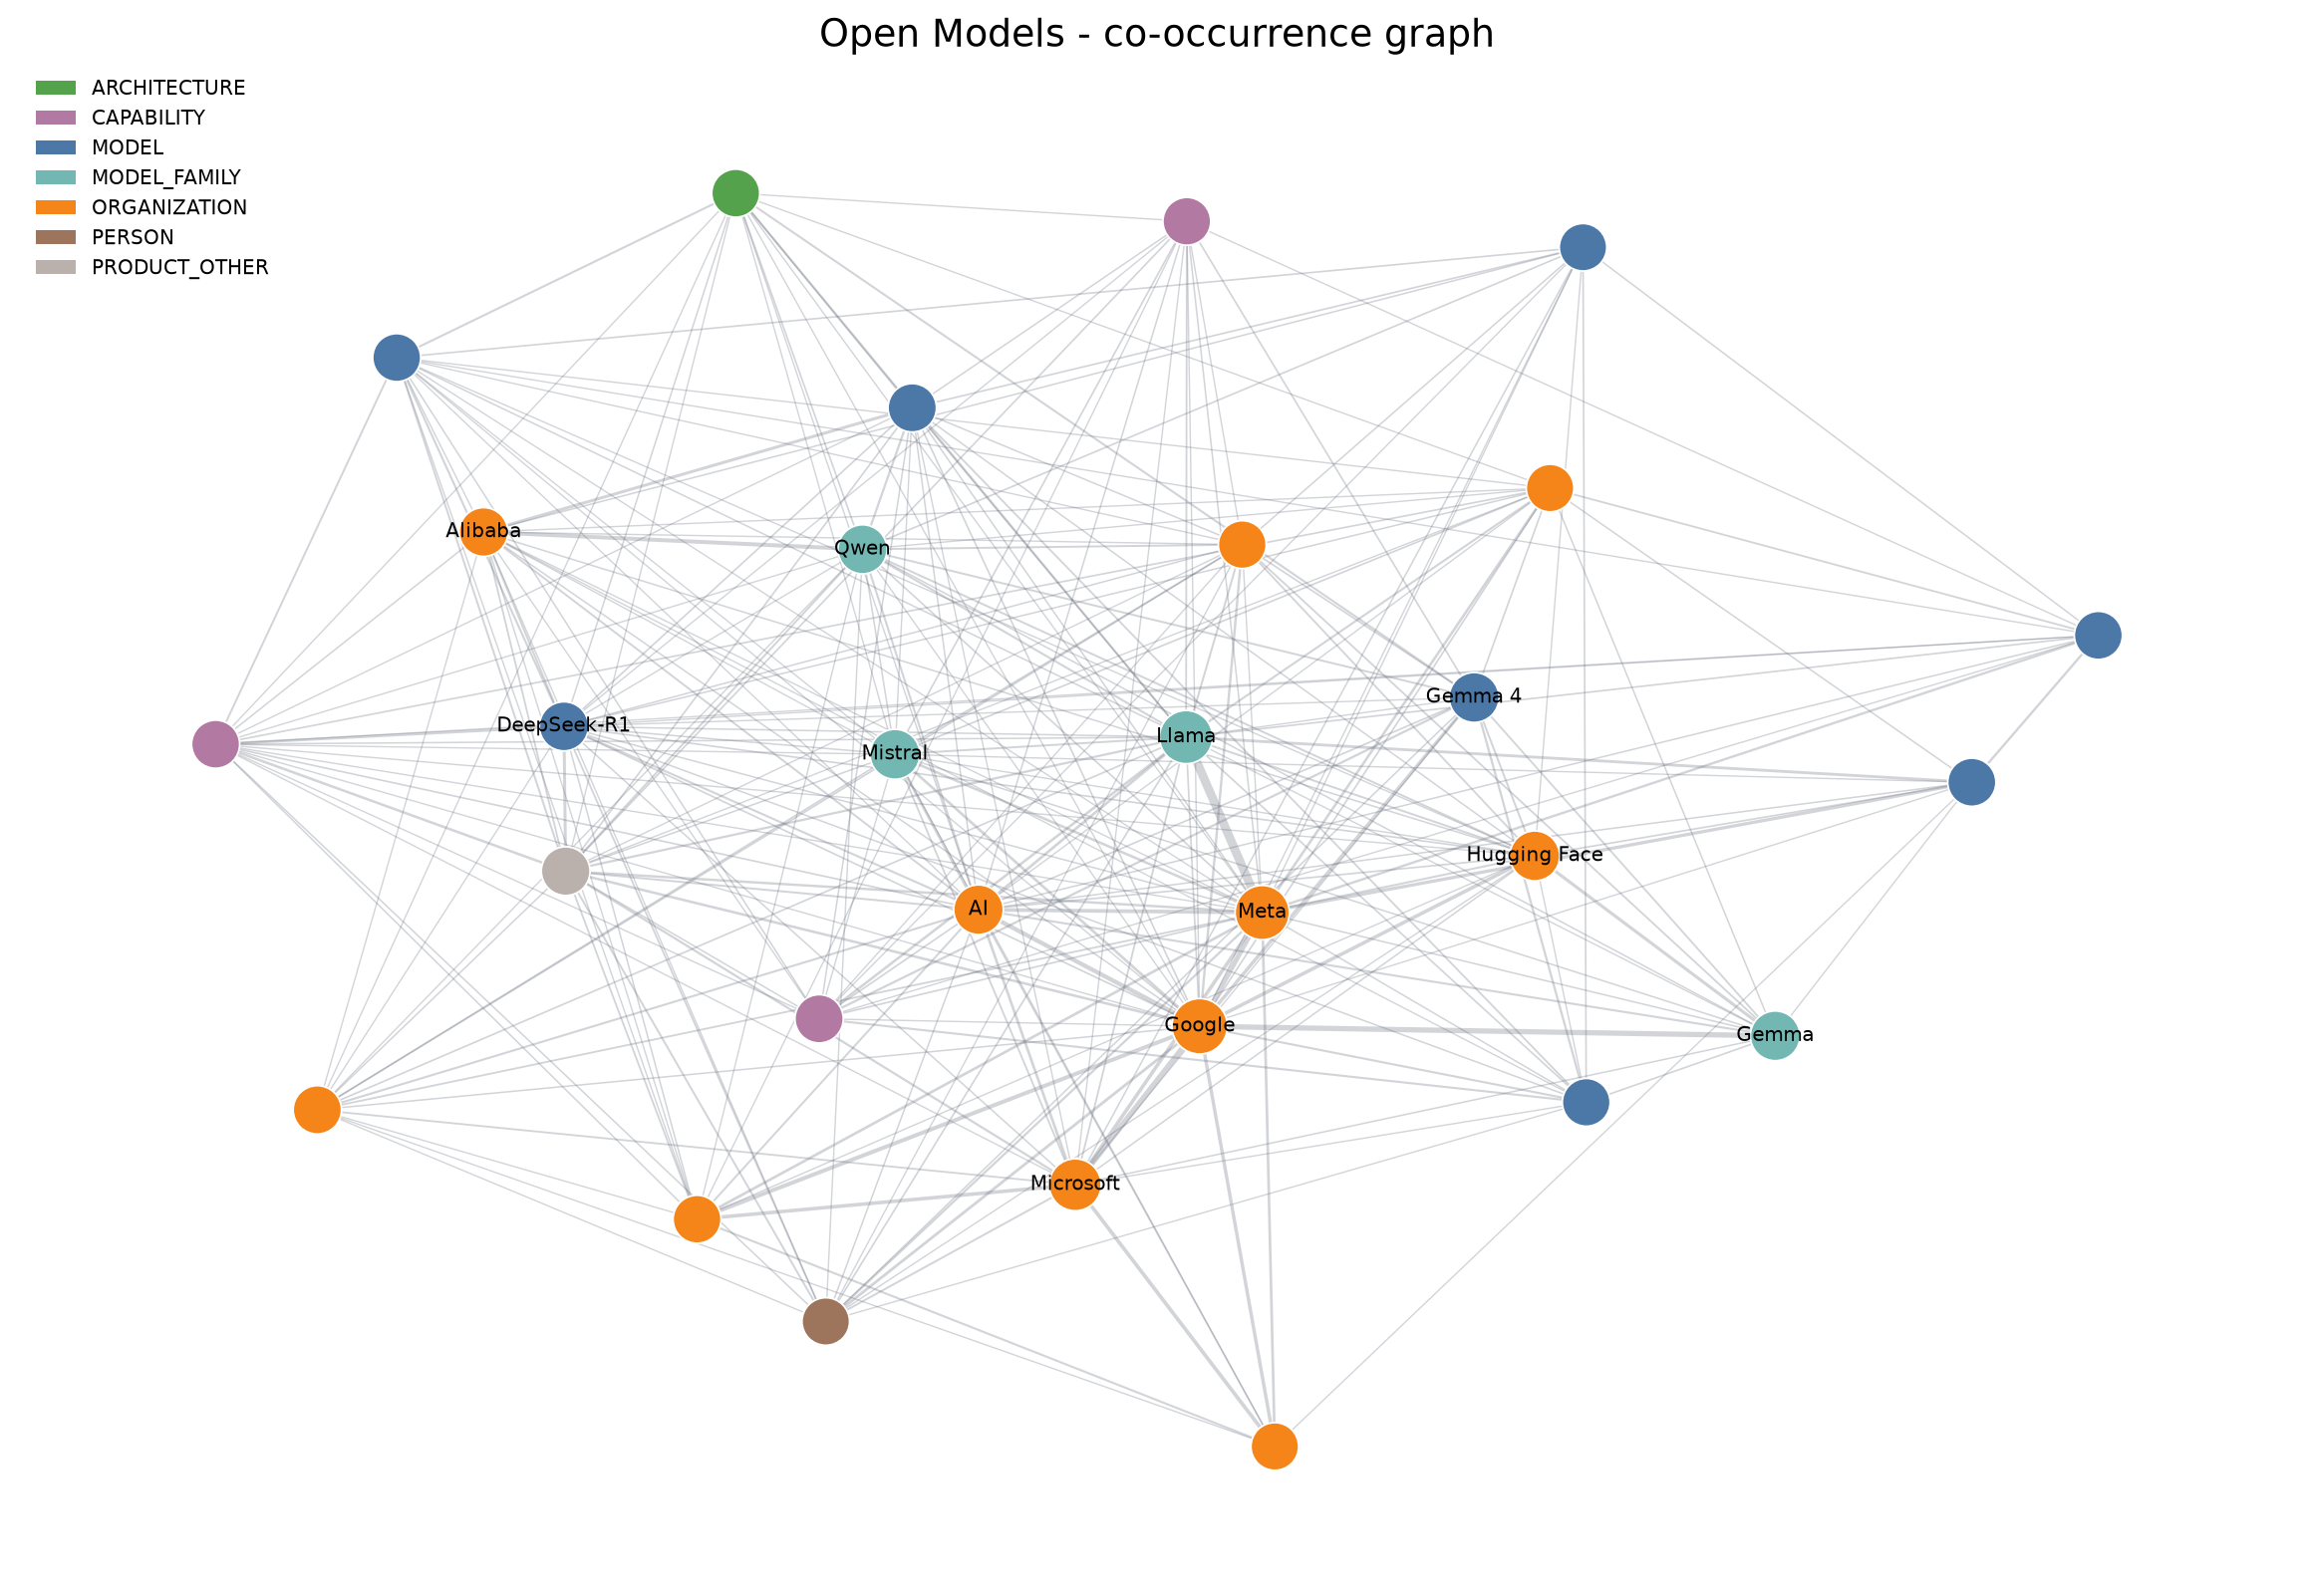

typed_pagerank_top15.png


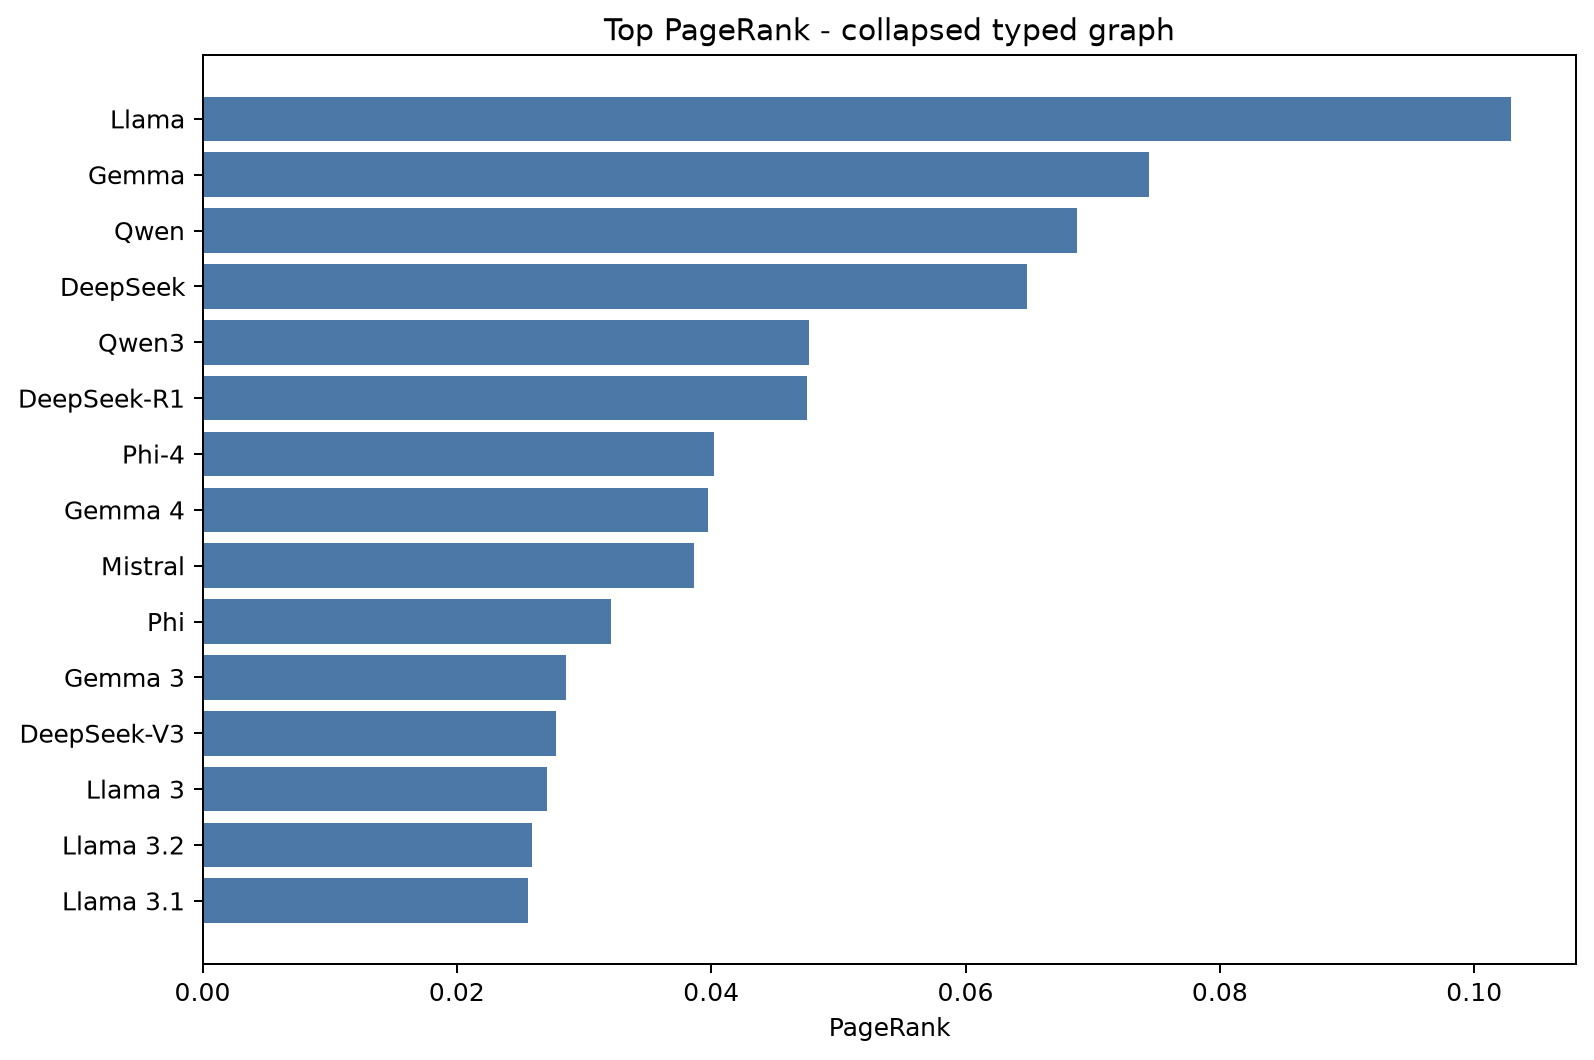

developer_release_subgraph.png


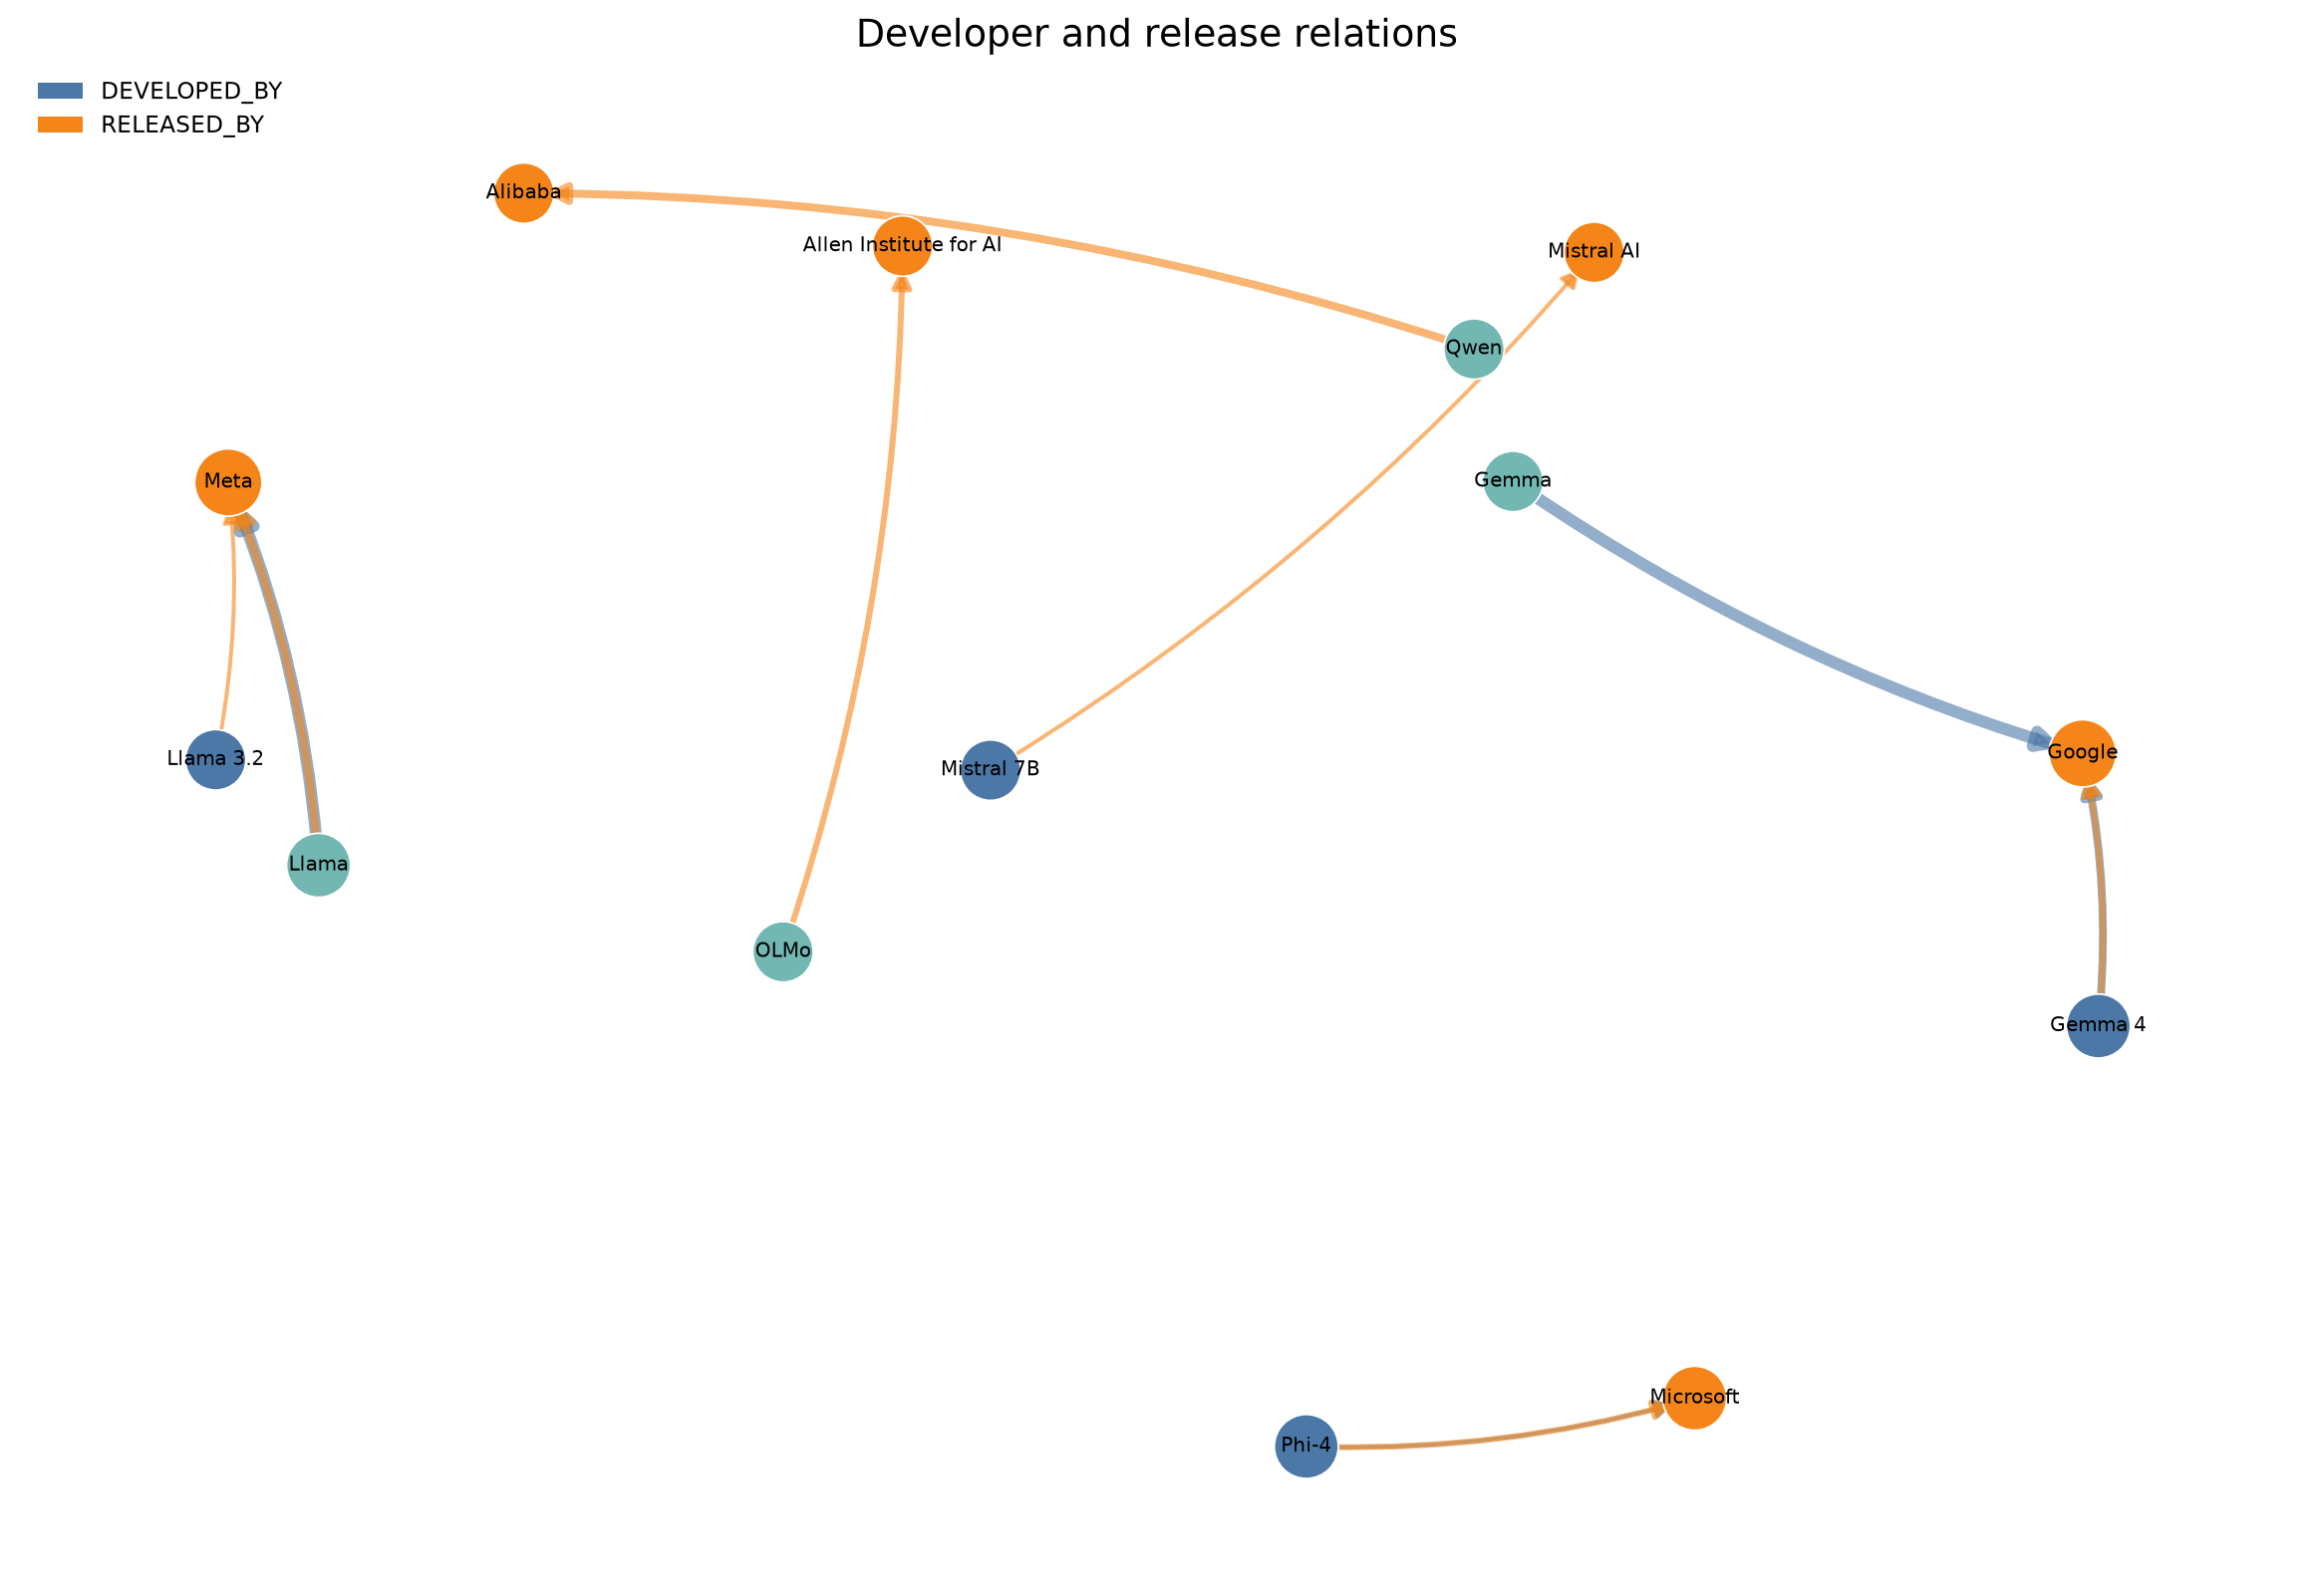

model_attributes_subgraph.png


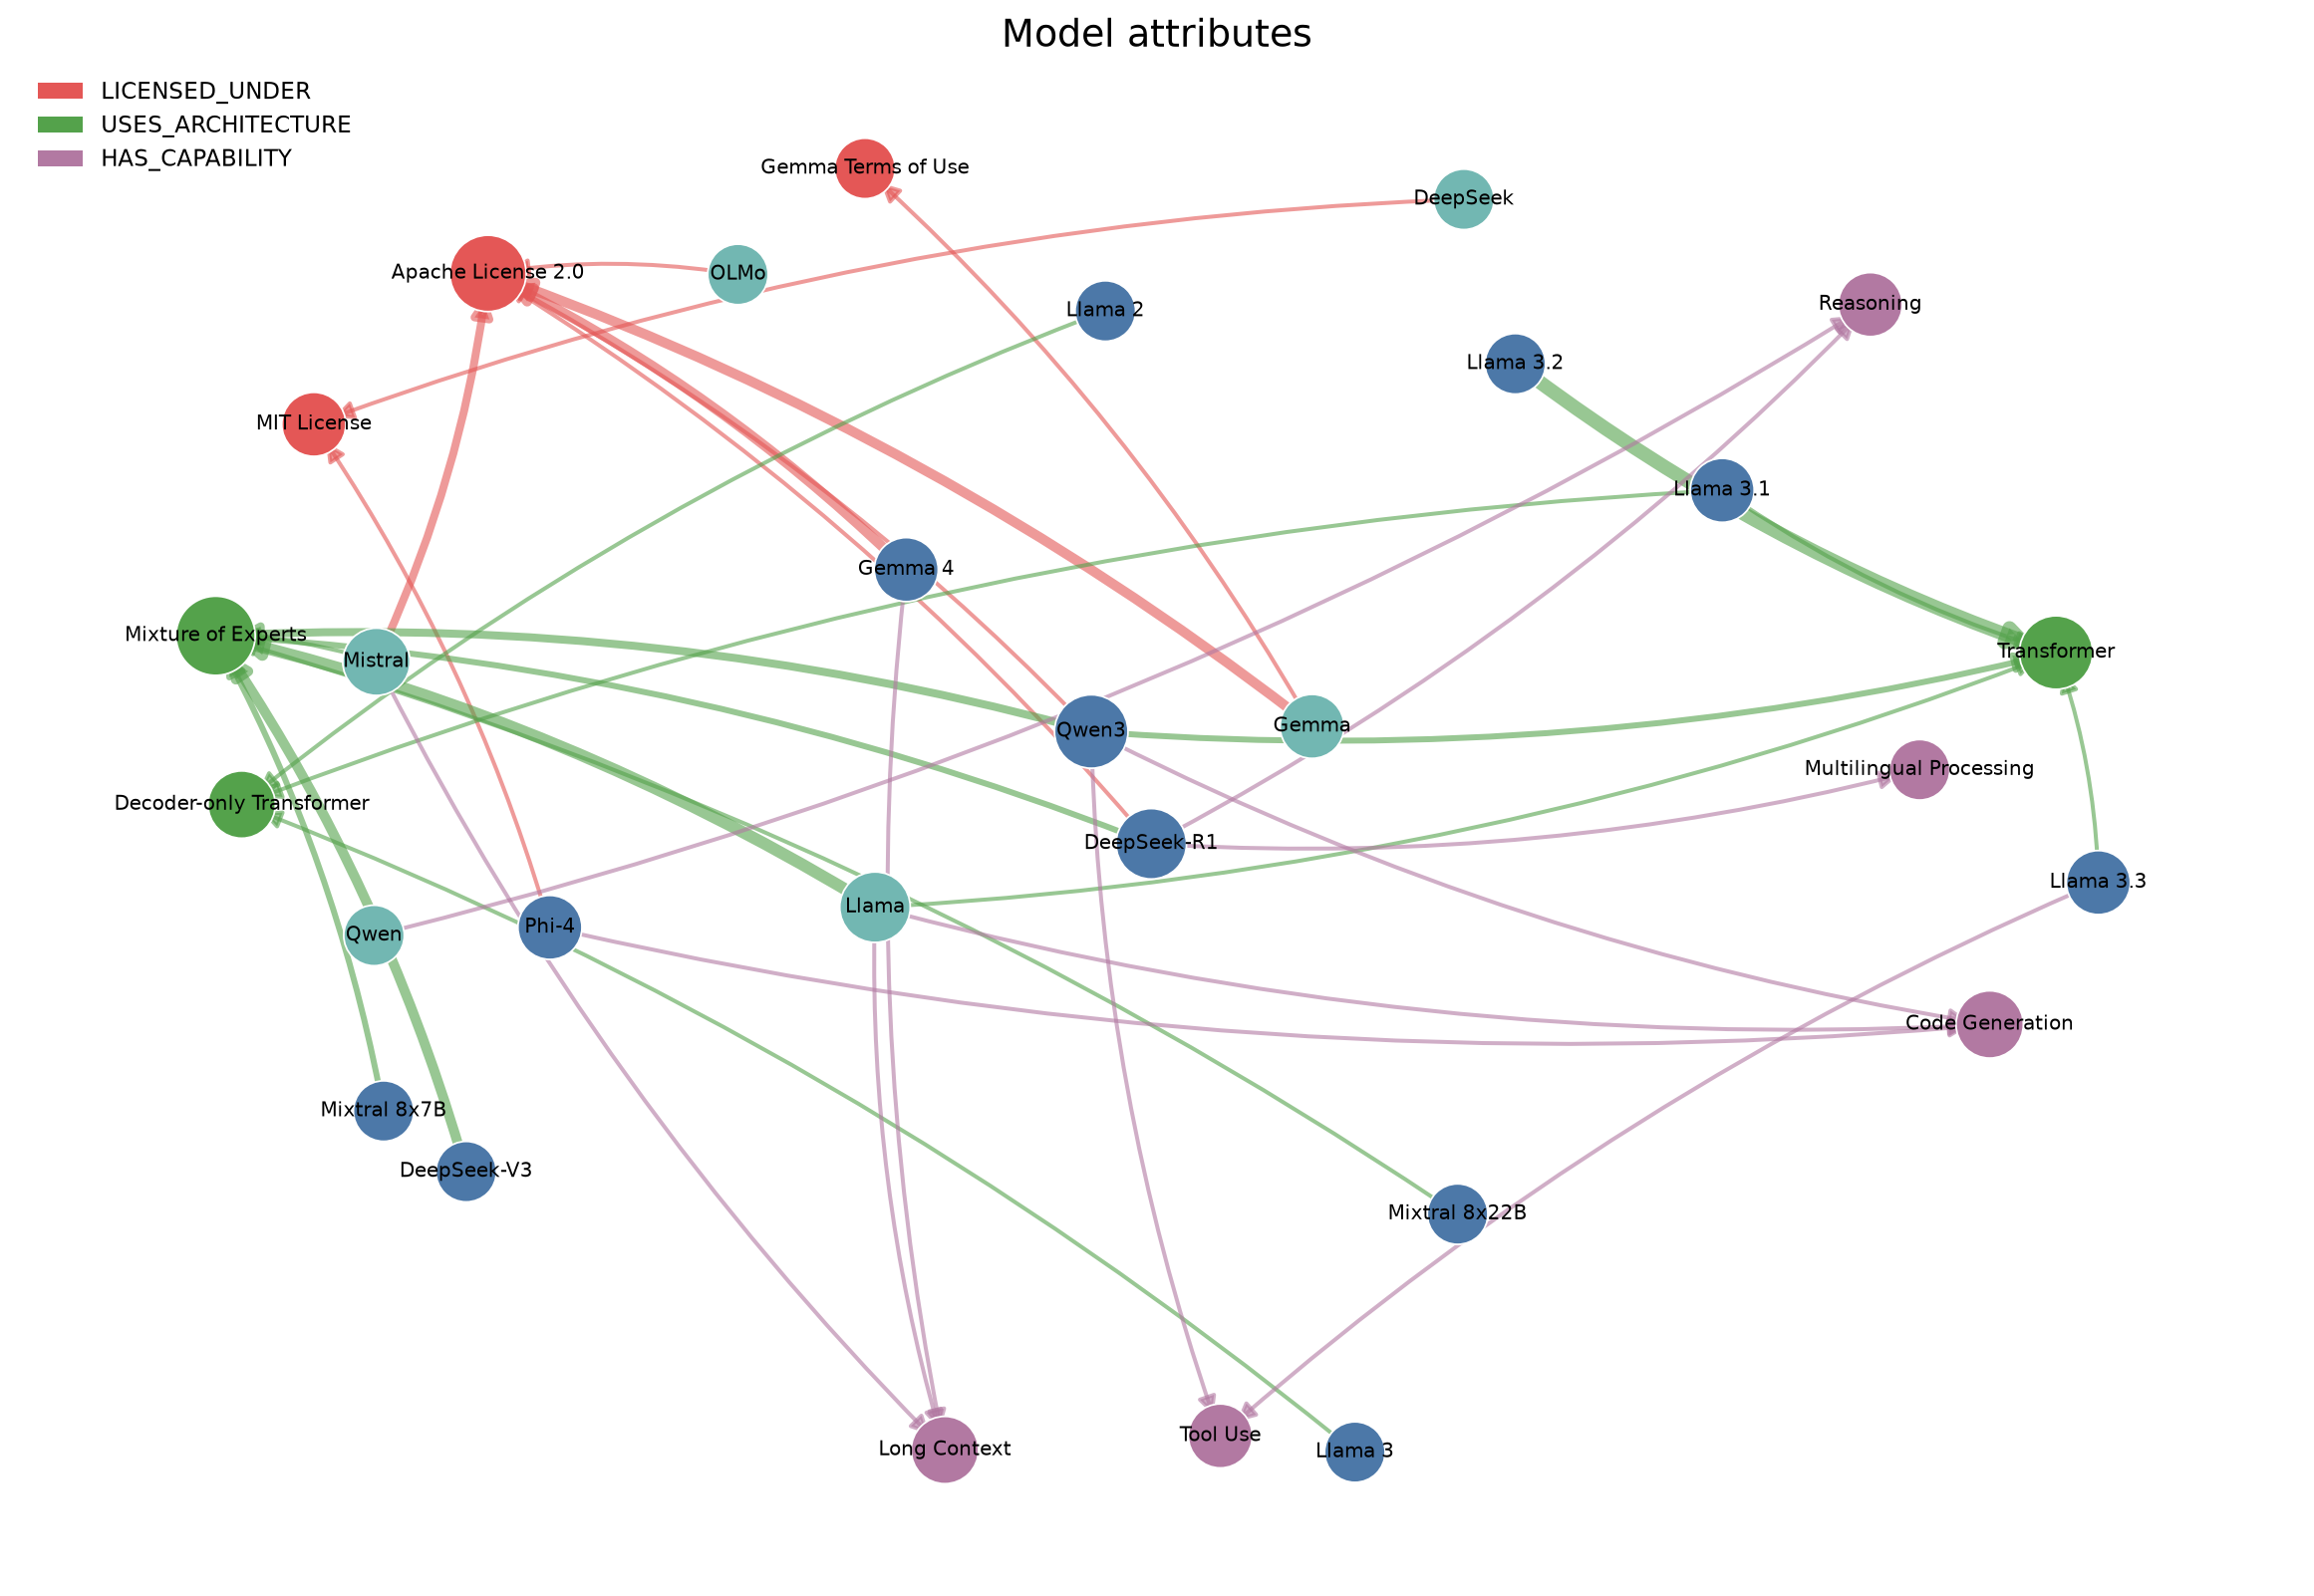

relation_type_counts.png


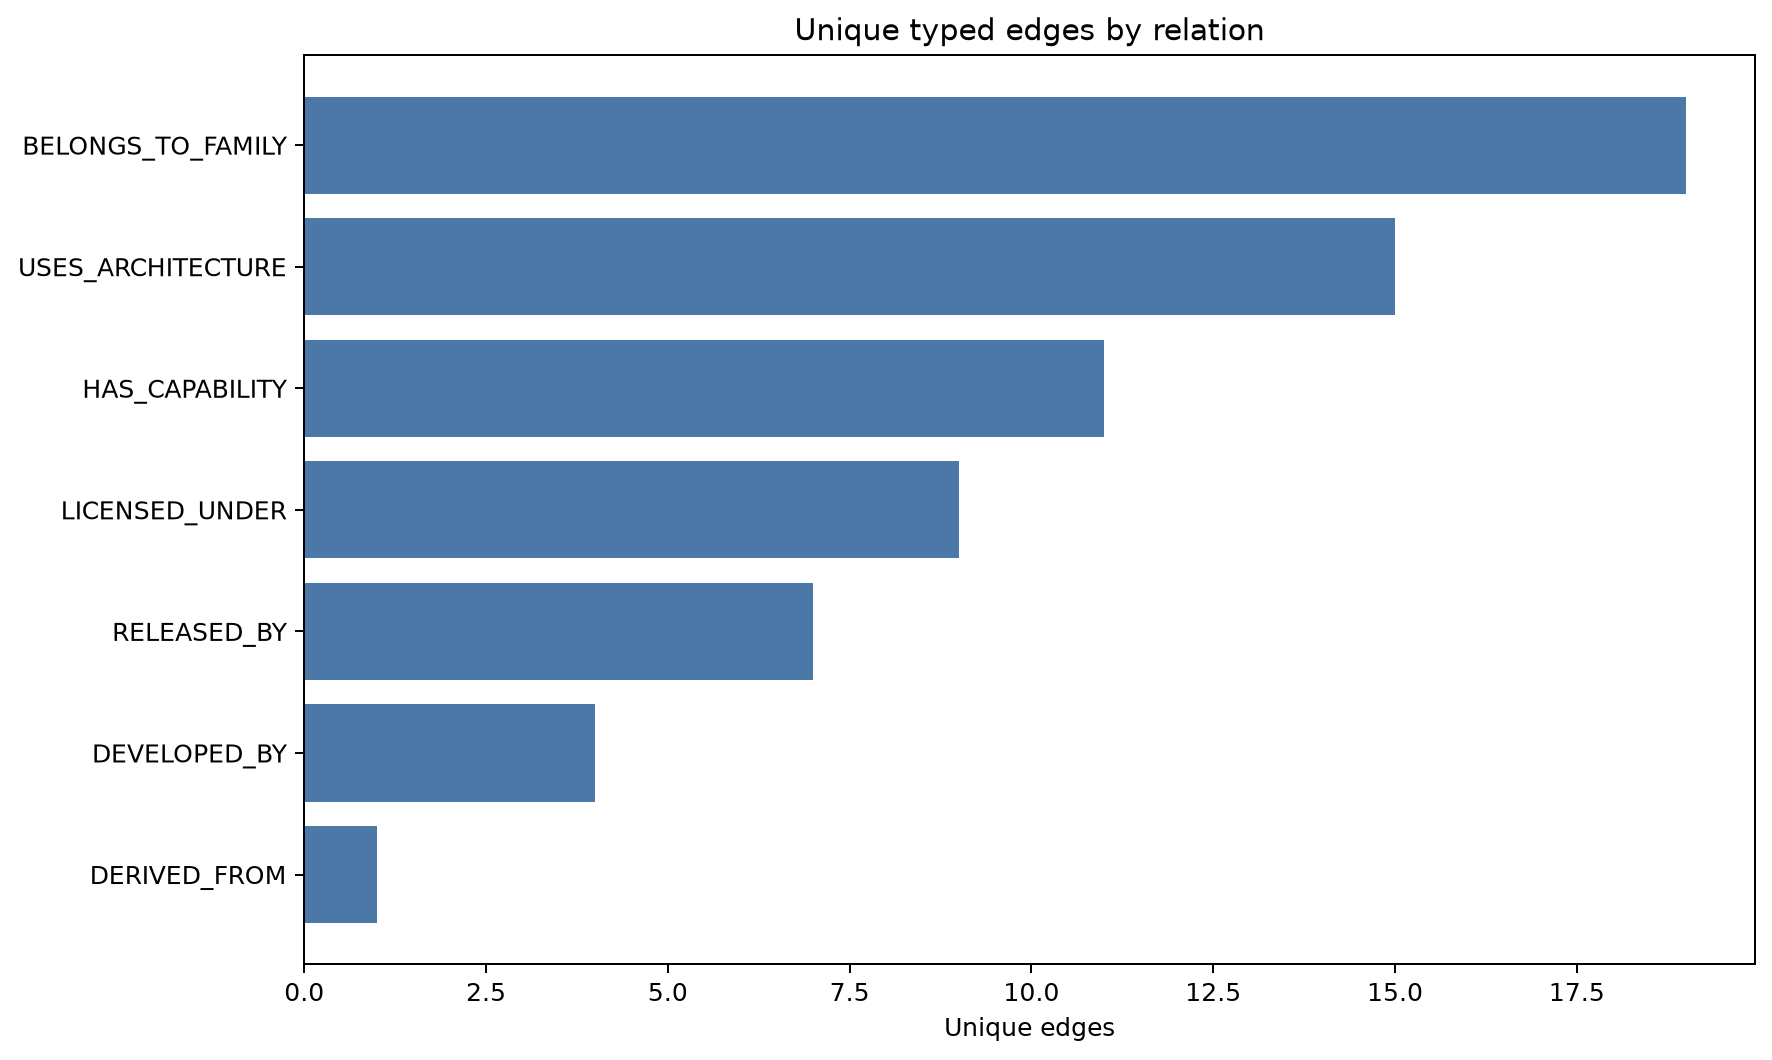

monthly_relation_assertions.png


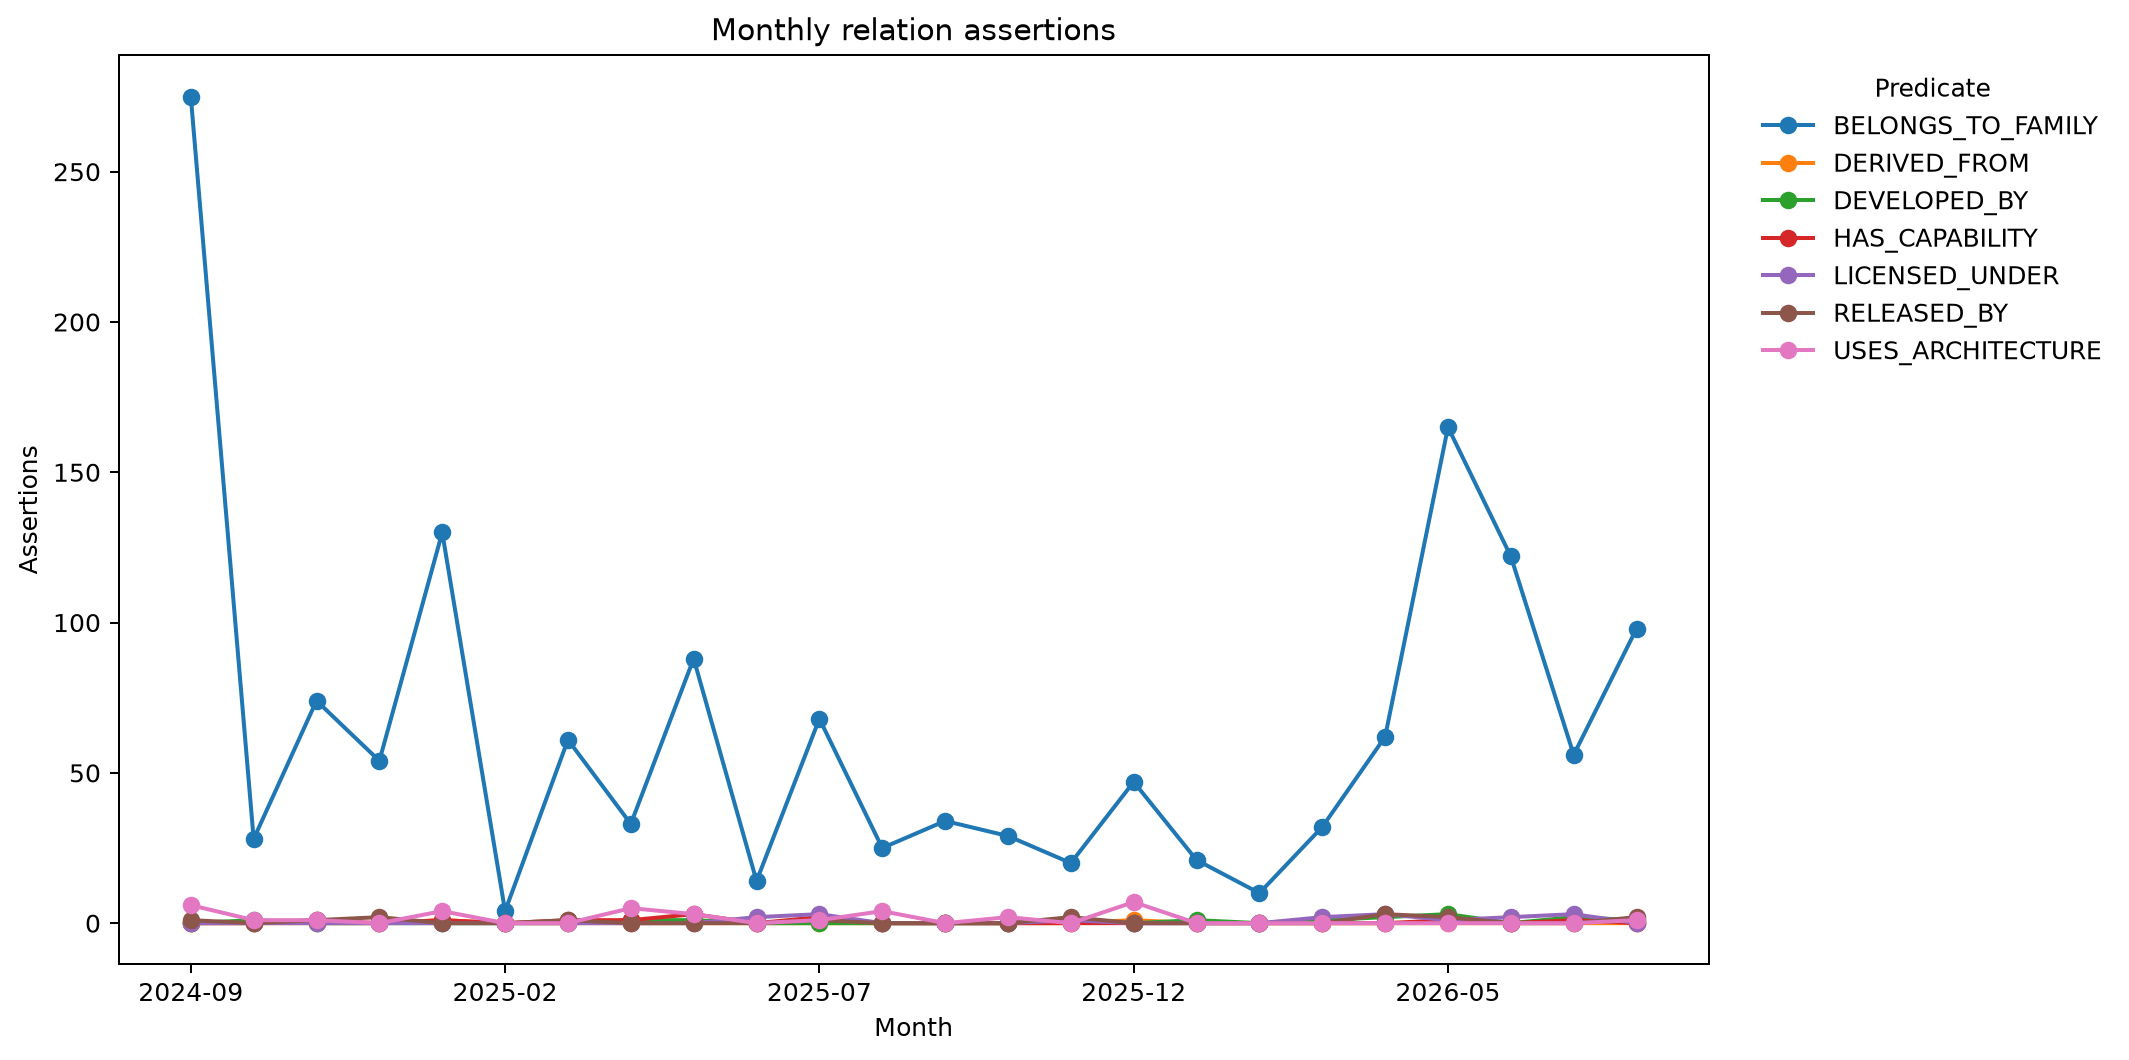

cooccurrence_community_sizes.png


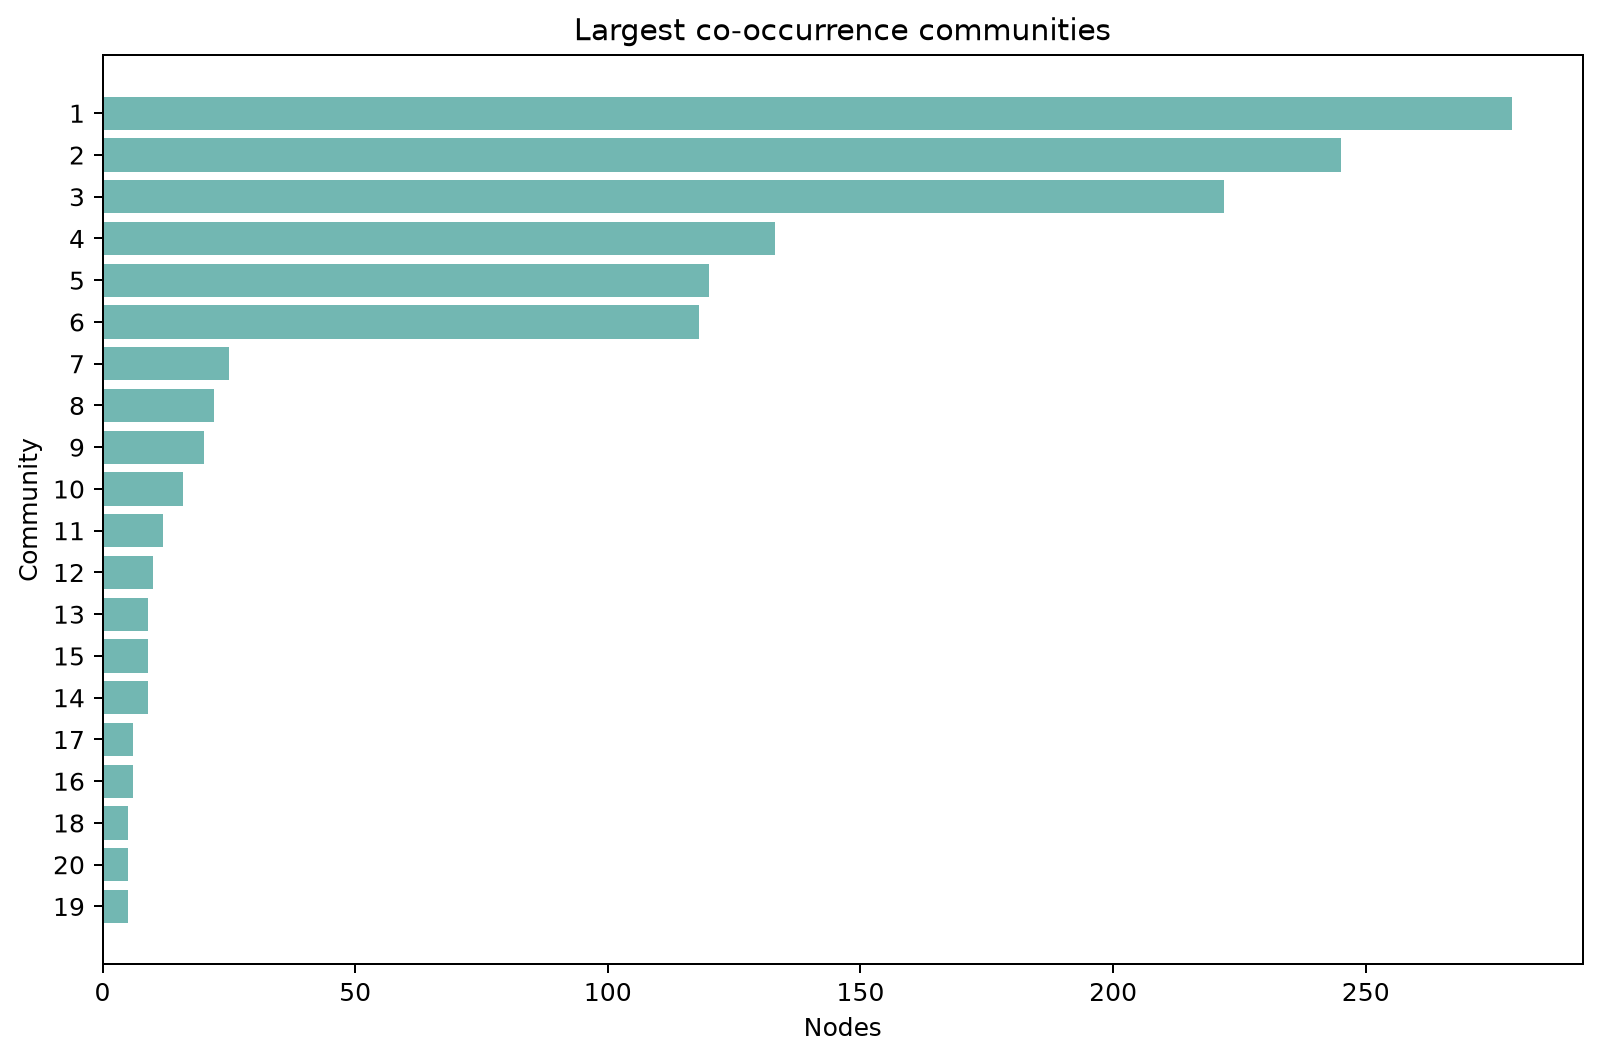

In [11]:
for filename in [
    "typed_graph_top.png",
    "cooccurrence_graph_top.png",
    "typed_pagerank_top15.png",
    "developer_release_subgraph.png",
    "model_attributes_subgraph.png",
    "relation_type_counts.png",
    "monthly_relation_assertions.png",
    "cooccurrence_community_sizes.png",
]:
    path = WP3_OUTPUT_DIR / "figures" / filename
    print(filename)
    display(Image(filename=str(path)))

전체 graph와 관계별 subgraph, 시간 변화, community 크기를 각각 분리했다.
최종 제출 전에는 label 겹침과 threshold를 확인하고, 발표에 사용할 그림은 해당 finding의
원문 evidence와 함께 선택한다.

## 11. 공식 WP2가 도착했을 때 교체 절차

In [12]:
handoff_checklist = pd.DataFrame([
    (1, "새 WP2 폴더를 별도 위치에 보존한다."),
    (2, "entities/relations 및 선택 테이블의 실제 파일명을 확인한다."),
    (3, "계약 JSON의 files와 column aliases를 갱신한다."),
    (4, "공식 evidence 필드가 확정되면 strict_provenance=true로 바꾼다."),
    (5, "새 output directory를 지정하고 RUN_PIPELINE=True로 실행한다."),
    (6, "contract_report와 validation_report를 먼저 확인한다."),
    (7, "assertion 수, collapsed edge 수, relation type 분포를 파일럿과 비교한다."),
    (8, "수동 review 결과를 반영한 뒤 metric과 시각화를 확정한다."),
], columns=["step", "action"])
handoff_checklist

,step,action
0,1,새 WP2 폴더를 별도 위치에 보존한다.
1,2,entities/relations 및 선택 테이블의 실제 파일명을 확인한다.
2,3,계약 JSON의 files와 column aliases를 갱신한다.
3,4,공식 evidence 필드가 확정되면 strict_provenance=true로 바꾼다.
4,5,새 output directory를 지정하고 RUN_PIPELINE=True로 실행한다.
5,6,contract_report와 validation_report를 먼저 확인한다.
6,7,"assertion 수, collapsed edge 수, relation type 분..."
7,8,수동 review 결과를 반영한 뒤 metric과 시각화를 확정한다.


## 12. 평가기준과 Stage 3 handoff

이 파이프라인은 Stage 1 평가기준의 schema 정의, node/edge 구성, centrality와 clustering,
NetworkX 시각화, graph/schema 저장을 지원한다. 하지만 최종 Stage 1 제출을 위해서는 다음이
추가되어야 한다. Predicate별 분석·시간 변화·community·evidence 후보는 자동 생성된다.
공식 입력 후 남는 일은 수동 검수 precision 확정, evidence 기반 insight 승인, 팀원 contribution과
AI tool disclosure 기록이다.

공식 Stage 3 Graph-RAG를 위해서는 다음 chain을 보존한다.

`entity_id → relation_id → text_unit_id → document_id → URL / published_at`

그래프가 찾은 relation만 답변 근거로 사용하지 않고, 연결된 원문 passage를 함께 retrieval해야
faithfulness와 temporal grounding을 평가할 수 있다.

## 13. 현재 상태

이 노트북과 출력은 **WP3 pipeline integration baseline**이다. 공식 WP2 계약이 도착하기 전에는
파일럿의 graph 수치로 최종 결론을 내리지 않는다. 계약이 확정되면 adapter validation을 먼저
통과시키고, 동일 notebook을 재실행해 최종 analysis artifact를 만든다.